<a href="https://colab.research.google.com/github/sabbirpuspo/breast-skin-brain-lesion-segmentation/blob/main/Breast_Skin_Brain_Lesion_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q -U kagglehub pandas pillow matplotlib scikit-learn

import kagglehub
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

DATASETS = {
    "busi": "aryashah2k/breast-ultrasound-images-dataset",
    "isic2016": "mahmudulhasantasin/isic-2016-original-dataset",
    "lgg": "mateuszbuda/lgg-mri-segmentation",
}

# Start with BUSI.
# Later choose "isic2016" or "lgg".
DATASET = "busi"

data_root = Path(
    kagglehub.dataset_download(DATASETS[DATASET])
)

print("Selected dataset:", DATASET)
print("Kaggle location:", data_root)
print("Dataset directory exists:", data_root.is_dir())

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 68.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 68.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 69.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
Using Colab cache for faster access to the 'breast-ultrasound-images

In [2]:
from collections import Counter

all_files = sorted(
    p for p in data_root.rglob("*")
    if p.is_file()
)

print("Total files:", len(all_files))

print("\nFile types:")
print(Counter(p.suffix.lower() for p in all_files))

print("\nFirst 25 files:")
for p in all_files[:25]:
    print(p.relative_to(data_root))

Total files: 1578

File types:
Counter({'.png': 1578})

First 25 files:
Dataset_BUSI_with_GT/benign/benign (1).png
Dataset_BUSI_with_GT/benign/benign (1)_mask.png
Dataset_BUSI_with_GT/benign/benign (10).png
Dataset_BUSI_with_GT/benign/benign (10)_mask.png
Dataset_BUSI_with_GT/benign/benign (100).png
Dataset_BUSI_with_GT/benign/benign (100)_mask.png
Dataset_BUSI_with_GT/benign/benign (100)_mask_1.png
Dataset_BUSI_with_GT/benign/benign (101).png
Dataset_BUSI_with_GT/benign/benign (101)_mask.png
Dataset_BUSI_with_GT/benign/benign (102).png
Dataset_BUSI_with_GT/benign/benign (102)_mask.png
Dataset_BUSI_with_GT/benign/benign (103).png
Dataset_BUSI_with_GT/benign/benign (103)_mask.png
Dataset_BUSI_with_GT/benign/benign (104).png
Dataset_BUSI_with_GT/benign/benign (104)_mask.png
Dataset_BUSI_with_GT/benign/benign (105).png
Dataset_BUSI_with_GT/benign/benign (105)_mask.png
Dataset_BUSI_with_GT/benign/benign (106).png
Dataset_BUSI_with_GT/benign/benign (106)_mask.png
Dataset_BUSI_with_GT/benign

In [3]:
import re
from collections import defaultdict

IMAGE_TYPES = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def build_records(root, dataset):

    files = sorted(
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_TYPES
    )

    records = []

    if dataset == "busi":

        categories = {"benign", "malignant", "normal"}

        def category(p):
            return next(
                (x.lower() for x in reversed(p.parent.parts)
                 if x.lower() in categories),
                None
            )

        mask_map = defaultdict(list)

        for p in files:
            if category(p) and "_mask" in p.stem.lower():
                key = (
                    p.parent,
                    p.stem.lower().split("_mask")[0]
                )
                mask_map[key].append(p)

        for p in files:

            label = category(p)

            if label and "_mask" not in p.stem.lower():

                masks = mask_map.get(
                    (p.parent, p.stem.lower()), []
                )

                if label != "normal" and not masks:
                    raise ValueError(
                        f"Missing BUSI mask: {p}"
                    )

                records.append({
                    "image": p,
                    "masks": masks,
                    "group": f"{label}:{p.stem}",
                    "label": label,
                    "partition": "unspecified"
                })

    elif dataset == "isic2016":

        image_map = {}
        mask_map = {}

        for p in files:

            if (
                p.suffix.lower() in {".jpg", ".jpeg"}
                and re.fullmatch(
                    r"ISIC_\d+", p.stem, flags=re.I
                )
            ):
                key = p.stem.upper()

                if key in image_map:
                    raise ValueError(
                        f"Duplicate ISIC image: {key}"
                    )

                image_map[key] = p

            elif (
                p.suffix.lower() == ".png"
                and re.fullmatch(
                    r"ISIC_\d+_segmentation",
                    p.stem,
                    flags=re.I
                )
            ):
                key = p.stem[:-len("_segmentation")].upper()

                if key in mask_map:
                    raise ValueError(
                        f"Duplicate ISIC mask: {key}"
                    )

                mask_map[key] = p

        for key, image in sorted(image_map.items()):

            if key not in mask_map:
                raise ValueError(
                    f"Missing ISIC mask: {key}"
                )

            parent = str(image.parent).lower()

            partition = (
                "test" if "test" in parent
                else "train" if "train" in parent
                else "unknown"
            )

            records.append({
                "image": image,
                "masks": [mask_map[key]],
                "group": key,
                "label": "lesion",
                "partition": partition
            })

    elif dataset == "lgg":

        for p in files:

            if p.suffix.lower() not in {".tif", ".tiff"}:
                continue

            if p.stem.lower().endswith("_mask"):
                continue

            mask = p.with_name(
                p.stem + "_mask" + p.suffix
            )

            if not mask.is_file():
                raise ValueError(
                    f"Missing LGG mask: {p}"
                )

            records.append({
                "image": p,
                "masks": [mask],
                "group": p.parent.name,
                "label": "lgg",
                "partition": "unspecified"
            })

    else:
        raise ValueError(f"Unknown dataset: {dataset}")

    if not records:
        raise ValueError(
            "No image-mask pairs found. "
            "Inspect the dataset folder structure."
        )

    return records


records = build_records(data_root, DATASET)

print("Matched images:", len(records))
print("First record:", records[0])

Matched images: 780
First record: {'image': PosixPath('/kaggle/input/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (1).png'), 'masks': [PosixPath('/kaggle/input/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (1)_mask.png')], 'group': 'benign:benign (1)', 'label': 'benign', 'partition': 'unspecified'}


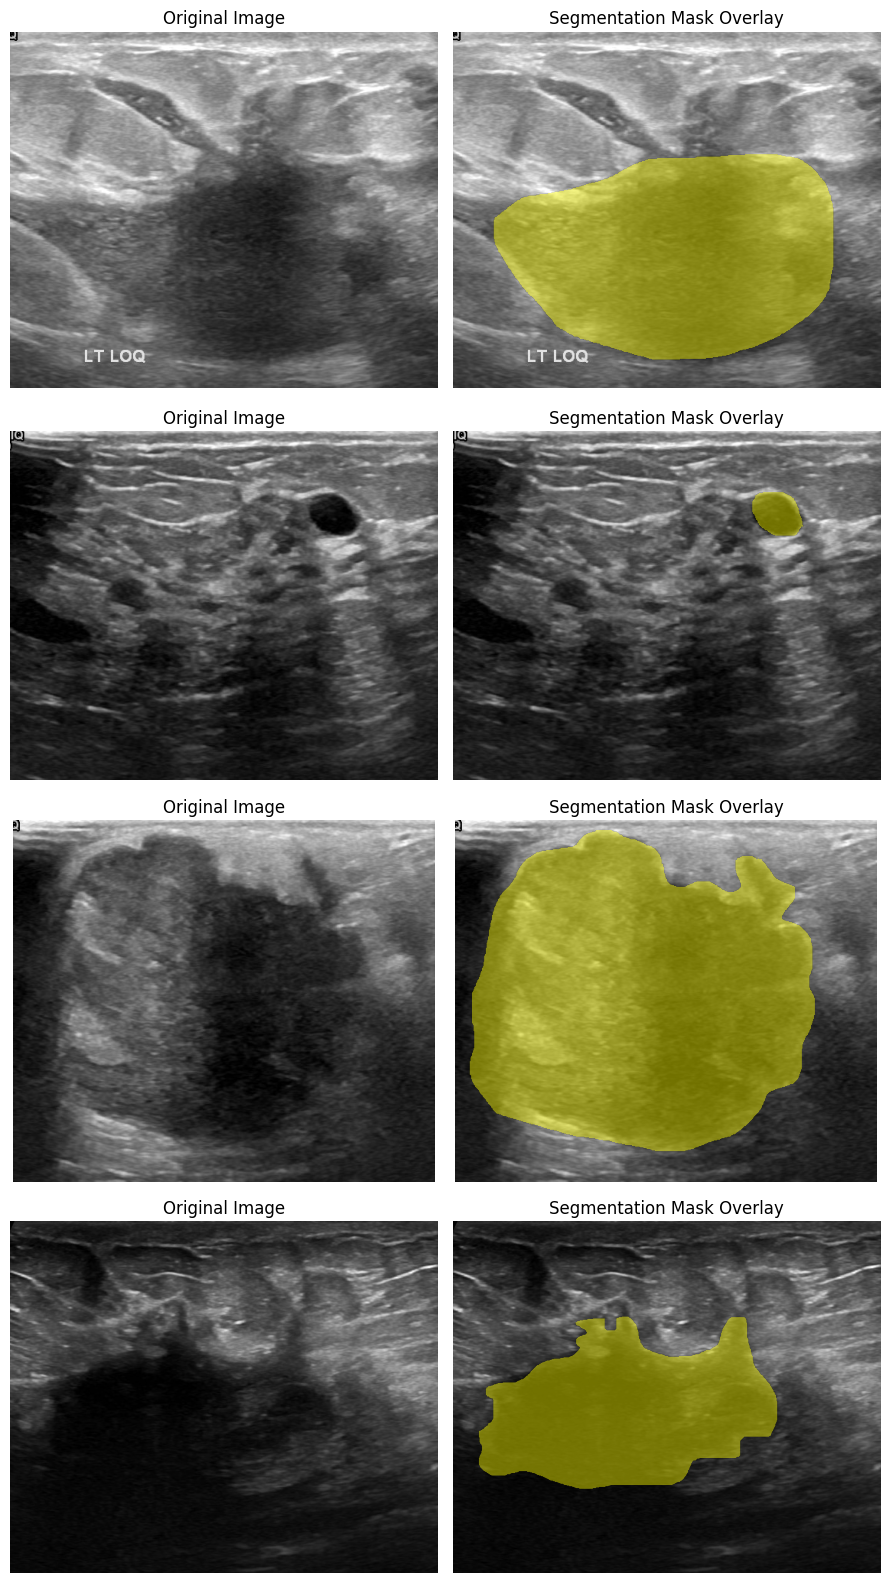

In [4]:
from PIL import Image

def load_image_and_mask(record):

    image = np.asarray(
        Image.open(record["image"]).convert("RGB")
    )

    mask = np.zeros(image.shape[:2], dtype=bool)

    for path in record["masks"]:

        current = np.asarray(
            Image.open(path).convert("L")
        )

        if current.shape != mask.shape:
            raise ValueError(
                f"Image-mask size mismatch: {path}"
            )

        mask |= current > 127

    return image, mask


rng = np.random.default_rng(42)

selected = rng.choice(
    len(records),
    size=min(4, len(records)),
    replace=False
)

fig, axes = plt.subplots(
    len(selected), 2,
    figsize=(9, 4 * len(selected)),
    squeeze=False
)

for row, index in enumerate(selected):

    record = records[int(index)]
    image, mask = load_image_and_mask(record)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title("Original Image")

    axes[row, 1].imshow(image)

    overlay = np.ma.masked_where(~mask, mask)
    axes[row, 1].imshow(
        overlay,
        cmap="autumn",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    axes[row, 1].set_title("Segmentation Mask Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit
)

SEED = 42
indices = np.arange(len(records))

if DATASET == "busi":

    labels = np.array([r["label"] for r in records])

    train, remaining = train_test_split(
        indices,
        test_size=0.30,
        stratify=labels,
        random_state=SEED
    )

    val, test = train_test_split(
        remaining,
        test_size=0.50,
        stratify=labels[remaining],
        random_state=SEED
    )

elif DATASET == "isic2016":

    partitions = np.array([
        r["partition"] for r in records
    ])

    if "unknown" in partitions:
        raise ValueError(
            "Cannot verify the official ISIC train/test "
            "partition from these file paths."
        )

    official_train = indices[partitions == "train"]
    test = indices[partitions == "test"]

    if len(official_train) == 0:
        raise ValueError("No official ISIC training images found.")

    train, val = train_test_split(
        official_train,
        test_size=0.20,
        random_state=SEED
    )

    if len(test) == 0:
        print(
            "Warning: Official test masks are not available "
            "in this mirror. Do not report test results."
        )

elif DATASET == "lgg":

    groups = np.array([r["group"] for r in records])

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.30,
        random_state=SEED
    )

    train_pos, other_pos = next(
        splitter.split(indices, groups=groups)
    )

    train = indices[train_pos]
    remaining = indices[other_pos]

    splitter2 = GroupShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=SEED
    )

    val_pos, test_pos = next(
        splitter2.split(
            remaining,
            groups=groups[remaining]
        )
    )

    val = remaining[val_pos]
    test = remaining[test_pos]

    assert set(groups[train]).isdisjoint(groups[val])
    assert set(groups[train]).isdisjoint(groups[test])
    assert set(groups[val]).isdisjoint(groups[test])


for name, subset in [
    ("train", train),
    ("val", val),
    ("test", test)
]:
    for index in subset:
        records[int(index)]["split"] = name

print("Training images:", len(train))
print("Validation images:", len(val))
print("Test images:", len(test))

Training images: 546
Validation images: 117
Test images: 117


In [6]:
import json

manifest = []

for record in records:

    manifest.append({
        "dataset": DATASET,
        "image": str(
            record["image"].relative_to(data_root)
        ),
        "masks": json.dumps([
            str(p.relative_to(data_root))
            for p in record["masks"]
        ]),
        "group": record["group"],
        "split": record["split"]
    })

manifest_path = Path(
    f"/content/{DATASET}_split_manifest.csv"
)

pd.DataFrame(manifest).to_csv(
    manifest_path,
    index=False
)

print("Manifest saved:", manifest_path)

Manifest saved: /content/busi_split_manifest.csv


In [7]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/"
    "IEEE_Medical_Lesion_Segmentation"
)

for folder in [
    "manifests",
    "checkpoints",
    "metrics",
    "figures",
    "logs"
]:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

shutil.copy2(
    manifest_path,
    PROJECT_DIR / "manifests" / manifest_path.name
)

print("Project results directory:", PROJECT_DIR)

Mounted at /content/drive
Project results directory: /content/drive/MyDrive/IEEE_Medical_Lesion_Segmentation


In [11]:
from pathlib import Path
from datetime import datetime, timezone

RUN_NAME = (
    f"{DATASET}_pilot_"
    + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
)

RUN_DIR = Path("/content/Medical_Lesion_Segmentation_Research") / RUN_NAME

RUN_DIR.mkdir(parents=True, exist_ok=True)

print("Experiment directory:", RUN_DIR)

Experiment directory: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z


In [13]:
%pip install -q --force-reinstall --no-cache-dir --no-deps Pillow==11.3.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 107.2 MB/s eta 0:00:00


In [14]:
import PIL
import torch

from PIL import Image, ImageDraw, ImageFont
from torchvision.models import resnet18, ResNet18_Weights

print("Pillow version:", PIL.__version__)
print("PyTorch version:", torch.__version__)
print("Pillow import: SUCCESS")
print("Torchvision ResNet-18 import: SUCCESS")

Pillow version: 11.3.0
PyTorch version: 2.11.0+cu130
Pillow import: SUCCESS
Torchvision ResNet-18 import: SUCCESS


In [15]:
%pip install -q kagglehub pandas matplotlib scikit-learn

In [16]:
import math
import random
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy import ndimage as ndi
from torchvision.models import resnet18, ResNet18_Weights

IMAGE_SIZE = 256

def adaptive_targets(y):
    """Create core, outer-support, and boundary-band targets."""

    y = np.asarray(y, dtype=bool)

    labels, n = ndi.label(
        y,
        structure=np.ones((3, 3), dtype=np.uint8)
    )

    core = np.zeros_like(y)
    outer = np.zeros_like(y)

    for k in range(1, n + 1):

        component = labels == k
        area = int(component.sum())

        radius = int(np.clip(
            math.floor(
                0.10 * math.sqrt(area / math.pi) + 0.5
            ),
            1, 8
        ))

        yy, xx = np.ogrid[
            -radius:radius + 1,
            -radius:radius + 1
        ]

        disk = (xx * xx + yy * yy) <= radius ** 2

        core |= ndi.binary_erosion(
            component, structure=disk, border_value=0
        )

        outer |= ndi.binary_dilation(
            component, structure=disk, border_value=0
        )

    band = outer & ~core

    return tuple(
        z.astype(np.float32)
        for z in (core, outer, band)
    )


class DecoderBlock(nn.Module):

    def __init__(self, channels, skip_channels, out_channels):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(
                channels + skip_channels,
                out_channels, 3, padding=1, bias=False
            ),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                3, padding=1, bias=False
            ),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x, skip):

        x = F.interpolate(
            x, size=skip.shape[-2:],
            mode="bilinear", align_corners=False
        )

        return self.net(torch.cat([x, skip], dim=1))


class RegionSeg(nn.Module):

    def __init__(self, variant="baseline", pretrained=True):
        super().__init__()

        assert variant in {"baseline", "proposed"}
        self.variant = variant

        weights = (
            ResNet18_Weights.DEFAULT if pretrained else None
        )

        encoder = resnet18(weights=weights)

        self.stem = nn.Sequential(
            encoder.conv1, encoder.bn1, encoder.relu
        )

        self.pool = encoder.maxpool
        self.l1 = encoder.layer1
        self.l2 = encoder.layer2
        self.l3 = encoder.layer3
        self.l4 = encoder.layer4

        self.up3 = DecoderBlock(512, 256, 128)
        self.up2 = DecoderBlock(128, 128, 96)
        self.up1 = DecoderBlock(96, 64, 64)
        self.up0 = DecoderBlock(64, 64, 32)
        self.high = DecoderBlock(32, 3, 24)

        if variant == "proposed":
            self.envelope = nn.Conv2d(64, 2, 1)
            self.head = nn.Conv2d(26, 1, 1)
        else:
            self.head = nn.Conv2d(24, 1, 1)

    def forward(self, x):

        s = self.stem(x)

        e1 = self.l1(self.pool(s))
        e2 = self.l2(e1)
        e3 = self.l3(e2)
        e4 = self.l4(e3)

        d3 = self.up3(e4, e3)
        d2 = self.up2(d3, e2)
        d1 = self.up1(d2, e1)
        d0 = self.up0(d1, s)

        features = self.high(d0, x)

        if self.variant == "baseline":
            return {"p": torch.sigmoid(self.head(features))}

        envelope = F.interpolate(
            self.envelope(d1),
            size=x.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Core probability
        c = torch.sigmoid(envelope[:, 0:1])

        # Outer-support probability
        o = c + (1 - c) * torch.sigmoid(
            envelope[:, 1:2]
        )

        # Fine allocation probability
        t = torch.sigmoid(
            self.head(torch.cat([features, c, o], dim=1))
        )

        # Final constrained prediction
        p = c + (o - c) * t

        return {"p": p, "c": c, "o": o, "t": t}


DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

for variant in ["baseline", "proposed"]:
    network = RegionSeg(variant, pretrained=False)
    print(
        variant,
        "parameters:",
        sum(p.numel() for p in network.parameters())
    )

Device: cuda
baseline parameters: 12702081
proposed parameters: 12702213


In [20]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class SegDataset(Dataset):

    def __init__(self, records, indices, augment=False):
        self.records = records
        self.indices = [int(i) for i in indices]
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):

        record = self.records[self.indices[index]]
        image, mask = load_image_and_mask(record)

        image = np.asarray(
            Image.fromarray(image).resize(
                (IMAGE_SIZE, IMAGE_SIZE),
                Image.Resampling.BILINEAR
            )
        )

        mask = np.asarray(
            Image.fromarray(
                (mask.astype(np.uint8) * 255)
            ).resize(
                (IMAGE_SIZE, IMAGE_SIZE),
                Image.Resampling.NEAREST
            )
        ) > 127

        if self.augment and random.random() < 0.5:
            image = np.fliplr(image)
            mask = np.fliplr(mask)

        core, outer, band = adaptive_targets(mask)

        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float() / 255.0

        mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
        std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

        image = (image - mean) / std

        return (
            image,
            torch.from_numpy(mask[None].astype("float32")),
            torch.from_numpy(core[None]),
            torch.from_numpy(outer[None]),
            torch.from_numpy(band[None])
        )


def region_loss(probability, target):

    p = probability.clamp(1e-6, 1 - 1e-6)

    bce = F.binary_cross_entropy(p, target)

    axes = (1, 2, 3)
    foreground = target.sum(dim=axes) > 0

    intersection = (p * target).sum(dim=axes)

    dice_loss = 1 - (
        (2 * intersection + 1) /
        (p.sum(dim=axes) + target.sum(dim=axes) + 1)
    )

    if foreground.any():
        dice_term = dice_loss[foreground].mean()
    else:
        dice_term = bce.new_zeros(())

    return bce + dice_term


def combined_loss(prediction, batch, variant):

    _, y, core, outer, band = batch

    loss = region_loss(prediction["p"], y)

    if variant == "proposed":

        envelope_loss = (
            region_loss(prediction["c"], core) +
            region_loss(prediction["o"], outer)
        ) / 2

        band_ce = F.binary_cross_entropy(
            prediction["t"].clamp(1e-6, 1 - 1e-6),
            y,
            reduction="none"
        )

        axes = (1, 2, 3)
        band_area = band.sum(dim=axes)
        valid = band_area > 0

        if valid.any():

            per_image_band_loss = (
                (band_ce * band).sum(dim=axes) /
                band_area.clamp_min(1)
            )

            allocation_loss = per_image_band_loss[valid].mean()

        else:
            allocation_loss = loss.new_zeros(())

        loss = (
            loss +
            0.30 * envelope_loss +
            0.25 * allocation_loss
        )

    return loss


@torch.no_grad()
def evaluate(model, loader):

    model.eval()

    total_loss = 0
    dice_scores = []
    iou_scores = []

    empty_count = 0
    empty_false_positives = 0

    for batch in loader:

        batch = tuple(x.to(DEVICE) for x in batch)

        prediction = model(batch[0])
        loss = combined_loss(
            prediction, batch, model.variant
        )

        total_loss += loss.item() * batch[0].shape[0]

        predicted = (
            prediction["p"] >= 0.5
        ).cpu().numpy()

        ground_truth = (
            batch[1] >= 0.5
        ).cpu().numpy()

        for pred, truth in zip(predicted, ground_truth):

            if truth.any():

                tp = np.logical_and(pred, truth).sum()
                fp = np.logical_and(pred, ~truth).sum()
                fn = np.logical_and(~pred, truth).sum()

                dice_scores.append(
                    2 * tp / max(1, 2 * tp + fp + fn)
                )

                iou_scores.append(
                    tp / max(1, tp + fp + fn)
                )

            else:
                empty_count += 1
                empty_false_positives += int(pred.any())

    return {
        "val_loss": total_loss / len(loader.dataset),
        "val_dice": float(np.mean(dice_scores))
                    if dice_scores else float("nan"),
        "val_iou": float(np.mean(iou_scores))
                   if iou_scores else float("nan"),
        "empty_fp_rate": (
            empty_false_positives / empty_count
            if empty_count else float("nan")
        )
    }

In [22]:

# ============================================================
# CELL 11: CORRECTED MODEL TRAINING AND VALIDATION
# Breast, Skin, and Brain Lesion Medical Image Segmentation
# Models: Baseline vs Proposed Region-Guided Network
# ============================================================

import os
import json
import time
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from datetime import datetime, timezone
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# 1. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

EPOCHS = 5
BATCH_SIZE = 8
SEED = 42
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4

EXPERIMENTS = ["baseline", "proposed"]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

USE_AMP = DEVICE.type == "cuda"

# Create experiment directory if not already defined
if "RUN_DIR" not in globals():

    RUN_NAME = (
        f"{DATASET}_pilot_" +
        datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    )

    RUN_DIR = (
        Path("/content/Medical_Lesion_Segmentation_Research")
        / RUN_NAME
    )
else:
    RUN_DIR = Path(RUN_DIR)
    RUN_NAME = RUN_DIR.name

RUN_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_dir = RUN_DIR / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("=" * 60)
print("MEDICAL IMAGE SEGMENTATION EXPERIMENT")
print("=" * 60)
print("Dataset:", DATASET)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Mixed precision:", USE_AMP)
print("Results directory:", RUN_DIR)
print("=" * 60)


# ------------------------------------------------------------
# 2. RANDOM SEED
# ------------------------------------------------------------

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)


# ------------------------------------------------------------
# 3. DATASETS AND VALIDATION LOADER
# ------------------------------------------------------------

train_dataset = SegDataset(
    records,
    train,
    augment=True
)

val_dataset = SegDataset(
    records,
    val,
    augment=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=USE_AMP
)

print("\nTraining samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))


# ------------------------------------------------------------
# 4. SAVE EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

config = {
    "dataset": DATASET,
    "kaggle_dataset": DATASETS[DATASET],
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "image_size": IMAGE_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "seed": SEED,
    "models": EXPERIMENTS,
    "device": str(DEVICE),
    "mixed_precision": USE_AMP,
    "evaluation": "validation only; test set unused"
}

config_path = RUN_DIR / "config.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)


# ------------------------------------------------------------
# 5. TRAINING STORAGE
# ------------------------------------------------------------

history = []
checkpoints = {}

history_path = RUN_DIR / "validation_history.csv"


# ------------------------------------------------------------
# 6. TRAIN BOTH MODELS
# ------------------------------------------------------------

for variant in EXPERIMENTS:

    print("\n" + "=" * 60)
    print("TRAINING MODEL:", variant.upper())
    print("=" * 60)

    # Same seed for a fair initial comparison
    set_seed(SEED)

    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=2,
        pin_memory=USE_AMP
    )

    # Initialize model
    model = RegionSeg(
        variant=variant,
        pretrained=True
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # Correct AMP GradScaler
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    checkpoint_path = (
        checkpoint_dir / f"{variant}_best.pt"
    )

    checkpoints[variant] = checkpoint_path

    best_dice = -1.0
    best_epoch = 0

    cumulative_time = 0.0

    # --------------------------------------------------------
    # EPOCH LOOP
    # --------------------------------------------------------

    for epoch in range(1, EPOCHS + 1):

        epoch_start = time.perf_counter()

        model.train()

        total_train_loss = 0.0

        # ----------------------------------------------------
        # TRAINING LOOP
        # ----------------------------------------------------

        for batch in train_loader:

            batch = tuple(
                tensor.to(
                    DEVICE,
                    non_blocking=USE_AMP
                )
                for tensor in batch
            )

            optimizer.zero_grad(set_to_none=True)

            # ================================================
            # FIX 1:
            # Use autocast ONLY for model forward pass
            # ================================================

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=USE_AMP
            ):

                prediction = model(batch[0])

            # ================================================
            # FIX 2:
            # Convert model outputs to float32
            # OUTSIDE autocast
            # ================================================

            prediction = {
                key: value.float()
                for key, value in prediction.items()
            }

            # ================================================
            # FIX 3:
            # Calculate BCE + Dice + auxiliary losses
            # OUTSIDE autocast
            # ================================================

            loss = combined_loss(
                prediction,
                batch,
                variant
            )

            # Check numerical stability
            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss detected. "
                    f"Model={variant}, Epoch={epoch}, "
                    f"Loss={loss.item()}"
                )

            # ================================================
            # FIX 4:
            # Backpropagation with gradient scaling
            # ================================================

            scaler.scale(loss).backward()

            scaler.step(optimizer)

            scaler.update()

            total_train_loss += (
                loss.detach().item() * batch[0].size(0)
            )

        # ----------------------------------------------------
        # TRAINING LOSS
        # ----------------------------------------------------

        train_loss = (
            total_train_loss / len(train_dataset)
        )

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        # evaluate() runs without autocast and computes
        # segmentation metrics on validation data.
        metrics = evaluate(
            model,
            val_loader
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        epoch_seconds = (
            time.perf_counter() - epoch_start
        )

        cumulative_time += epoch_seconds

        # ----------------------------------------------------
        # SAVE EPOCH RESULTS
        # ----------------------------------------------------

        row = {
            "model": variant,
            "epoch": epoch,
            "train_loss": float(train_loss),
            "epoch_seconds": float(epoch_seconds),
            "cumulative_seconds": float(cumulative_time),
            **metrics
        }

        history.append(row)

        # Save after every epoch
        pd.DataFrame(history).to_csv(
            history_path,
            index=False
        )

        # ----------------------------------------------------
        # SAVE BEST MODEL BASED ON VALIDATION DICE
        # ----------------------------------------------------

        current_dice = float(metrics["val_dice"])

        if (
            epoch == 1 or
            (
                np.isfinite(current_dice)
                and current_dice > best_dice
            )
        ):

            best_dice = current_dice
            best_epoch = epoch

            torch.save(
                {
                    "model": variant,
                    "epoch": epoch,
                    "state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "best_val_dice": best_dice,
                    "config": config
                },
                checkpoint_path
            )

        # ----------------------------------------------------
        # DISPLAY EPOCH RESULTS
        # ----------------------------------------------------

        print(
            f"Epoch [{epoch}/{EPOCHS}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {metrics['val_loss']:.4f} | "
            f"Val Dice: {metrics['val_dice']:.4f} | "
            f"Val IoU: {metrics['val_iou']:.4f} | "
            f"Time: {epoch_seconds:.1f}s"
        )

    # --------------------------------------------------------
    # MODEL TRAINING COMPLETED
    # --------------------------------------------------------

    print("\nModel training completed:", variant)
    print("Best validation Dice:", best_dice)
    print("Best epoch:", best_epoch)
    print("Checkpoint:", checkpoint_path)

    # Release model memory before training next model
    del model
    del optimizer
    del scaler

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 7. EXPERIMENT SUMMARY
# ------------------------------------------------------------

df = pd.DataFrame(history)

summary_rows = []

for variant in EXPERIMENTS:

    subset = df[df["model"] == variant].copy()

    best_idx = subset["val_dice"].idxmax()
    best_row = subset.loc[best_idx]

    summary_rows.append({
        "model": variant,
        "best_epoch": int(best_row["epoch"]),
        "best_val_dice": float(best_row["val_dice"]),
        "val_iou_at_best_dice": float(best_row["val_iou"]),
        "empty_fp_rate_at_best_dice": float(
            best_row["empty_fp_rate"]
        ),
        "total_training_seconds": float(
            subset["epoch_seconds"].sum()
        )
    })

summary = pd.DataFrame(summary_rows)

summary_path = RUN_DIR / "experiment_summary.csv"

summary.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 60)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 60)

print(summary.to_string(index=False))

print("\nSaved files:")
print("Training history:", history_path)
print("Experiment summary:", summary_path)
print("Configuration:", config_path)
print("Model checkpoints:", checkpoint_dir)

print("\nSUCCESS: Training and validation completed.")
print("Held-out test set has not been evaluated.")


MEDICAL IMAGE SEGMENTATION EXPERIMENT
Dataset: busi
Device: cuda
GPU: Tesla T4
Epochs: 5
Batch size: 8
Mixed precision: True
Results directory: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z

Training samples: 546
Validation samples: 117

TRAINING MODEL: BASELINE
Epoch [1/5] | Train Loss: 1.2303 | Val Loss: 1.0876 | Val Dice: 0.5593 | Val IoU: 0.4329 | Time: 16.8s
Epoch [2/5] | Train Loss: 1.0460 | Val Loss: 0.9945 | Val Dice: 0.6191 | Val IoU: 0.4922 | Time: 14.0s
Epoch [3/5] | Train Loss: 0.9465 | Val Loss: 0.9246 | Val Dice: 0.5966 | Val IoU: 0.4848 | Time: 14.0s
Epoch [4/5] | Train Loss: 0.8752 | Val Loss: 0.8718 | Val Dice: 0.6410 | Val IoU: 0.5224 | Time: 14.3s
Epoch [5/5] | Train Loss: 0.8002 | Val Loss: 0.7880 | Val Dice: 0.6906 | Val IoU: 0.5837 | Time: 14.2s

Model training completed: baseline
Best validation Dice: 0.6905804450517498
Best epoch: 5
Checkpoint: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/checkpoints/basel

BUSI EXPERIMENTAL RESULTS

Experiment directory: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z

Training history:
   model  epoch  train_loss  epoch_seconds  cumulative_seconds  val_loss  val_dice  val_iou  empty_fp_rate
baseline      1    1.230317      16.775607           16.775607  1.087616  0.559272 0.432866           1.00
baseline      2    1.045963      13.987038           30.762645  0.994516  0.619086 0.492192           1.00
baseline      3    0.946535      13.989811           44.752456  0.924594  0.596598 0.484781           0.85
baseline      4    0.875189      14.281506           59.033961  0.871766  0.640977 0.522352           1.00
baseline      5    0.800201      14.221966           73.255927  0.788001  0.690580 0.583738           0.60
proposed      1    1.575180      14.363291           14.363291  1.331841  0.630108 0.525777           0.15
proposed      2    1.222644      14.309007           28.672298  1.113127  0.639851 0.516225           0.60
pr

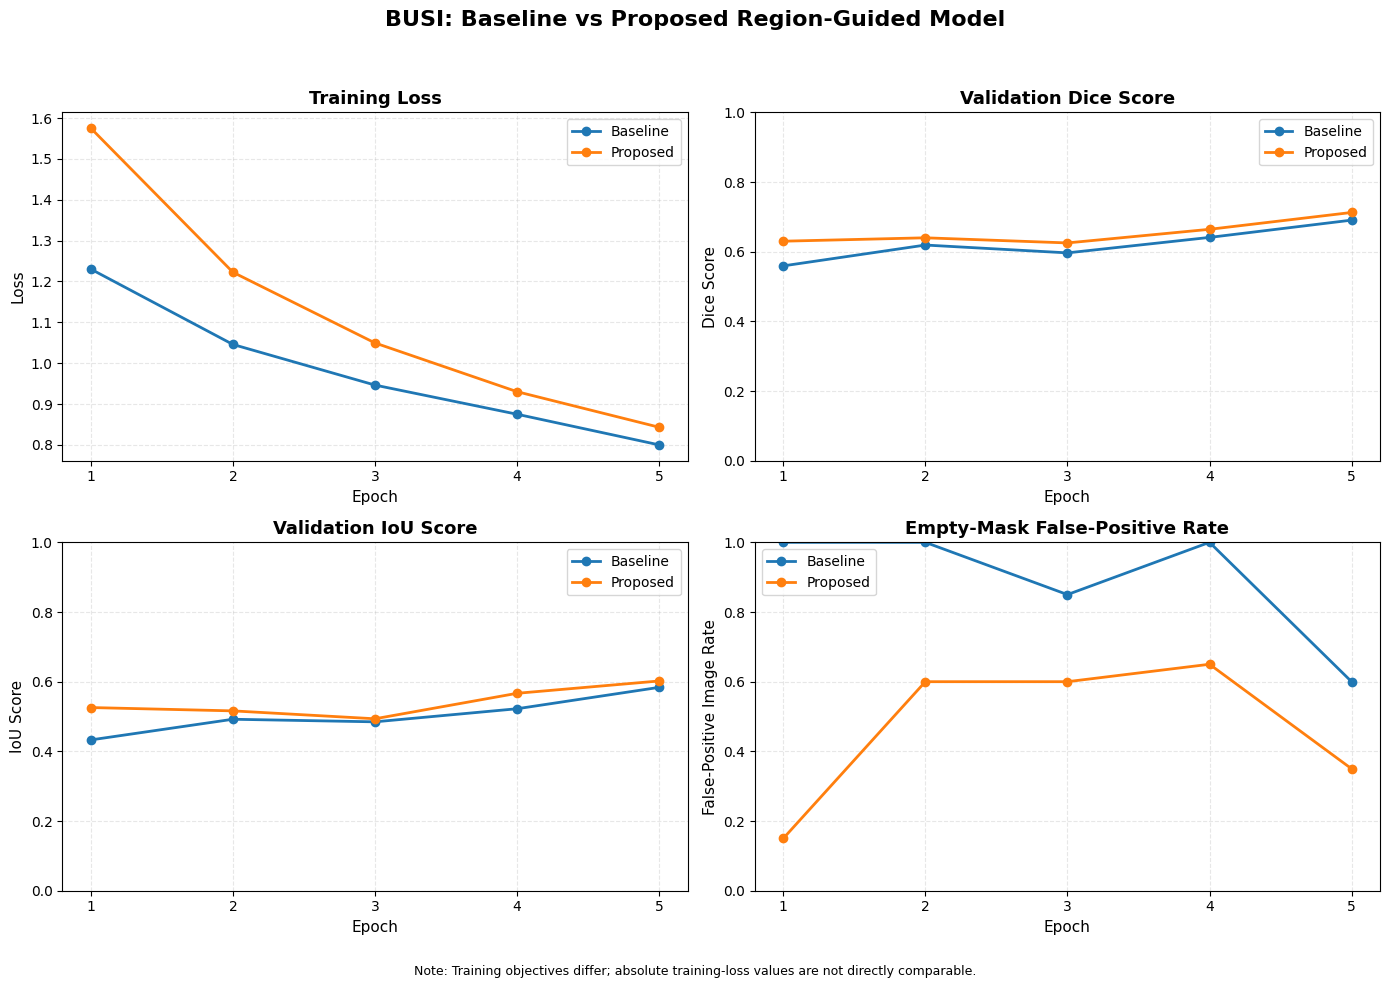


Experimental graph saved successfully!
File: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/BUSI_Experimental_Graphs.png

BASELINE VS PROPOSED MODEL COMPARISON
   Model  Best Epoch  Validation Dice  Validation IoU  Empty FP Rate
Baseline           5           0.6906          0.5837         0.6000
Proposed           5           0.7126          0.6020         0.3500

PERFORMANCE DIFFERENCES
------------------------------------------------------------
Dice difference: +0.0220 (+2.20 percentage points)
IoU difference: +0.0183 (+1.83 percentage points)
Empty FP rate difference: -0.2500 (-25.00 percentage points)

ALL OUTPUTS SAVED SUCCESSFULLY
Graph: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/BUSI_Experimental_Graphs.png
Comparison CSV: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/BUSI_Model_Comparison.csv
PNG size: 449.15 KB

Cell 11 completed successfully.
You can now proceed to Cell 12.


In [24]:

# ============================================================
# CELL 11: EXPERIMENTAL GRAPHS AND MODEL COMPARISON
# Breast, Skin, and Brain Lesion Medical Image Segmentation
#
# Dataset: BUSI
# Models: Baseline vs Proposed Region-Guided Model
#
# FIX: PNG output only; SVG export removed.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. LOAD SAVED EXPERIMENTAL RESULTS
# ------------------------------------------------------------

RUN_DIR = Path(RUN_DIR)

history_path = RUN_DIR / "validation_history.csv"

if not history_path.is_file():
    raise FileNotFoundError(
        f"Training history not found: {history_path}"
    )

df = pd.read_csv(history_path)

print("=" * 60)
print("BUSI EXPERIMENTAL RESULTS")
print("=" * 60)

print("\nExperiment directory:", RUN_DIR)
print("\nTraining history:")
print(df.to_string(index=False))

# ------------------------------------------------------------
# 2. VALIDATE REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "model",
    "epoch",
    "train_loss",
    "val_loss",
    "val_dice",
    "val_iou",
    "empty_fp_rate"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing columns in CSV: {missing}"
    )

for column in required_columns[1:]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

models = ["baseline", "proposed"]

for model_name in models:
    if df[df["model"] == model_name].empty:
        raise ValueError(
            f"No results found for {model_name}"
        )

# ------------------------------------------------------------
# 3. CREATE FOUR EXPERIMENTAL GRAPHS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

graphs = [
    (
        "train_loss",
        "Training Loss",
        "Loss"
    ),
    (
        "val_dice",
        "Validation Dice Score",
        "Dice Score"
    ),
    (
        "val_iou",
        "Validation IoU Score",
        "IoU Score"
    ),
    (
        "empty_fp_rate",
        "Empty-Mask False-Positive Rate",
        "False-Positive Image Rate"
    )
]

for ax, (metric, title, ylabel) in zip(
    axes.flatten(), graphs
):

    for model_name in models:

        subset = df[
            df["model"] == model_name
        ].sort_values("epoch")

        ax.plot(
            subset["epoch"],
            subset[metric],
            marker="o",
            linewidth=2,
            markersize=6,
            label=model_name.capitalize()
        )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Epoch", fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)

    ax.set_xticks(
        sorted(df["epoch"].dropna().unique())
    )

    if metric in [
        "val_dice",
        "val_iou",
        "empty_fp_rate"
    ]:
        ax.set_ylim(0, 1.0)

    ax.grid(
        True,
        linestyle="--",
        alpha=0.3
    )

    ax.legend(fontsize=10)

fig.suptitle(
    "BUSI: Baseline vs Proposed Region-Guided Model",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.5,
    0.015,
    "Note: Training objectives differ; "
    "absolute training-loss values are not directly comparable.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.04, 1, 0.95])

# ------------------------------------------------------------
# 4. SAVE PNG IMAGE (NO SVG)
# ------------------------------------------------------------

figure_path = RUN_DIR / "BUSI_Experimental_Graphs.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    format="png"
)

plt.show()
plt.close(fig)

print("\nExperimental graph saved successfully!")
print("File:", figure_path)

# ------------------------------------------------------------
# 5. CREATE MODEL COMPARISON TABLE
# ------------------------------------------------------------

comparison = []

for model_name in models:

    subset = df[
        df["model"] == model_name
    ].copy()

    subset = subset.dropna(
        subset=["val_dice"]
    )

    if subset.empty:
        raise ValueError(
            f"No valid Dice results for {model_name}"
        )

    best_row = subset.loc[
        subset["val_dice"].idxmax()
    ]

    comparison.append({
        "Model": model_name.capitalize(),
        "Best Epoch": int(best_row["epoch"]),
        "Validation Dice": float(
            best_row["val_dice"]
        ),
        "Validation IoU": float(
            best_row["val_iou"]
        ),
        "Empty FP Rate": float(
            best_row["empty_fp_rate"]
        )
    })

comparison_df = pd.DataFrame(comparison)

print("\n" + "=" * 60)
print("BASELINE VS PROPOSED MODEL COMPARISON")
print("=" * 60)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. CALCULATE PERFORMANCE DIFFERENCES
# ------------------------------------------------------------

baseline = comparison_df.iloc[0]
proposed = comparison_df.iloc[1]

dice_gain = (
    proposed["Validation Dice"]
    - baseline["Validation Dice"]
)

iou_gain = (
    proposed["Validation IoU"]
    - baseline["Validation IoU"]
)

fp_change = (
    proposed["Empty FP Rate"]
    - baseline["Empty FP Rate"]
)

print("\nPERFORMANCE DIFFERENCES")
print("-" * 60)

print(
    f"Dice difference: {dice_gain:+.4f} "
    f"({dice_gain * 100:+.2f} percentage points)"
)

print(
    f"IoU difference: {iou_gain:+.4f} "
    f"({iou_gain * 100:+.2f} percentage points)"
)

print(
    f"Empty FP rate difference: {fp_change:+.4f} "
    f"({fp_change * 100:+.2f} percentage points)"
)

# ------------------------------------------------------------
# 7. SAVE COMPARISON TABLE
# ------------------------------------------------------------

comparison_path = (
    RUN_DIR / "BUSI_Model_Comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("\n" + "=" * 60)
print("ALL OUTPUTS SAVED SUCCESSFULLY")
print("=" * 60)

print("Graph:", figure_path)
print("Comparison CSV:", comparison_path)

if figure_path.is_file():
    print(
        "PNG size:",
        round(
            figure_path.stat().st_size / 1024,
            2
        ),
        "KB"
    )

print("\nCell 11 completed successfully.")
print("You can now proceed to Cell 12.")


Loaded baseline: best checkpoint from epoch 5
Loaded proposed: best checkpoint from epoch 5
Foreground validation images: 97
Empty-mask validation images: 20


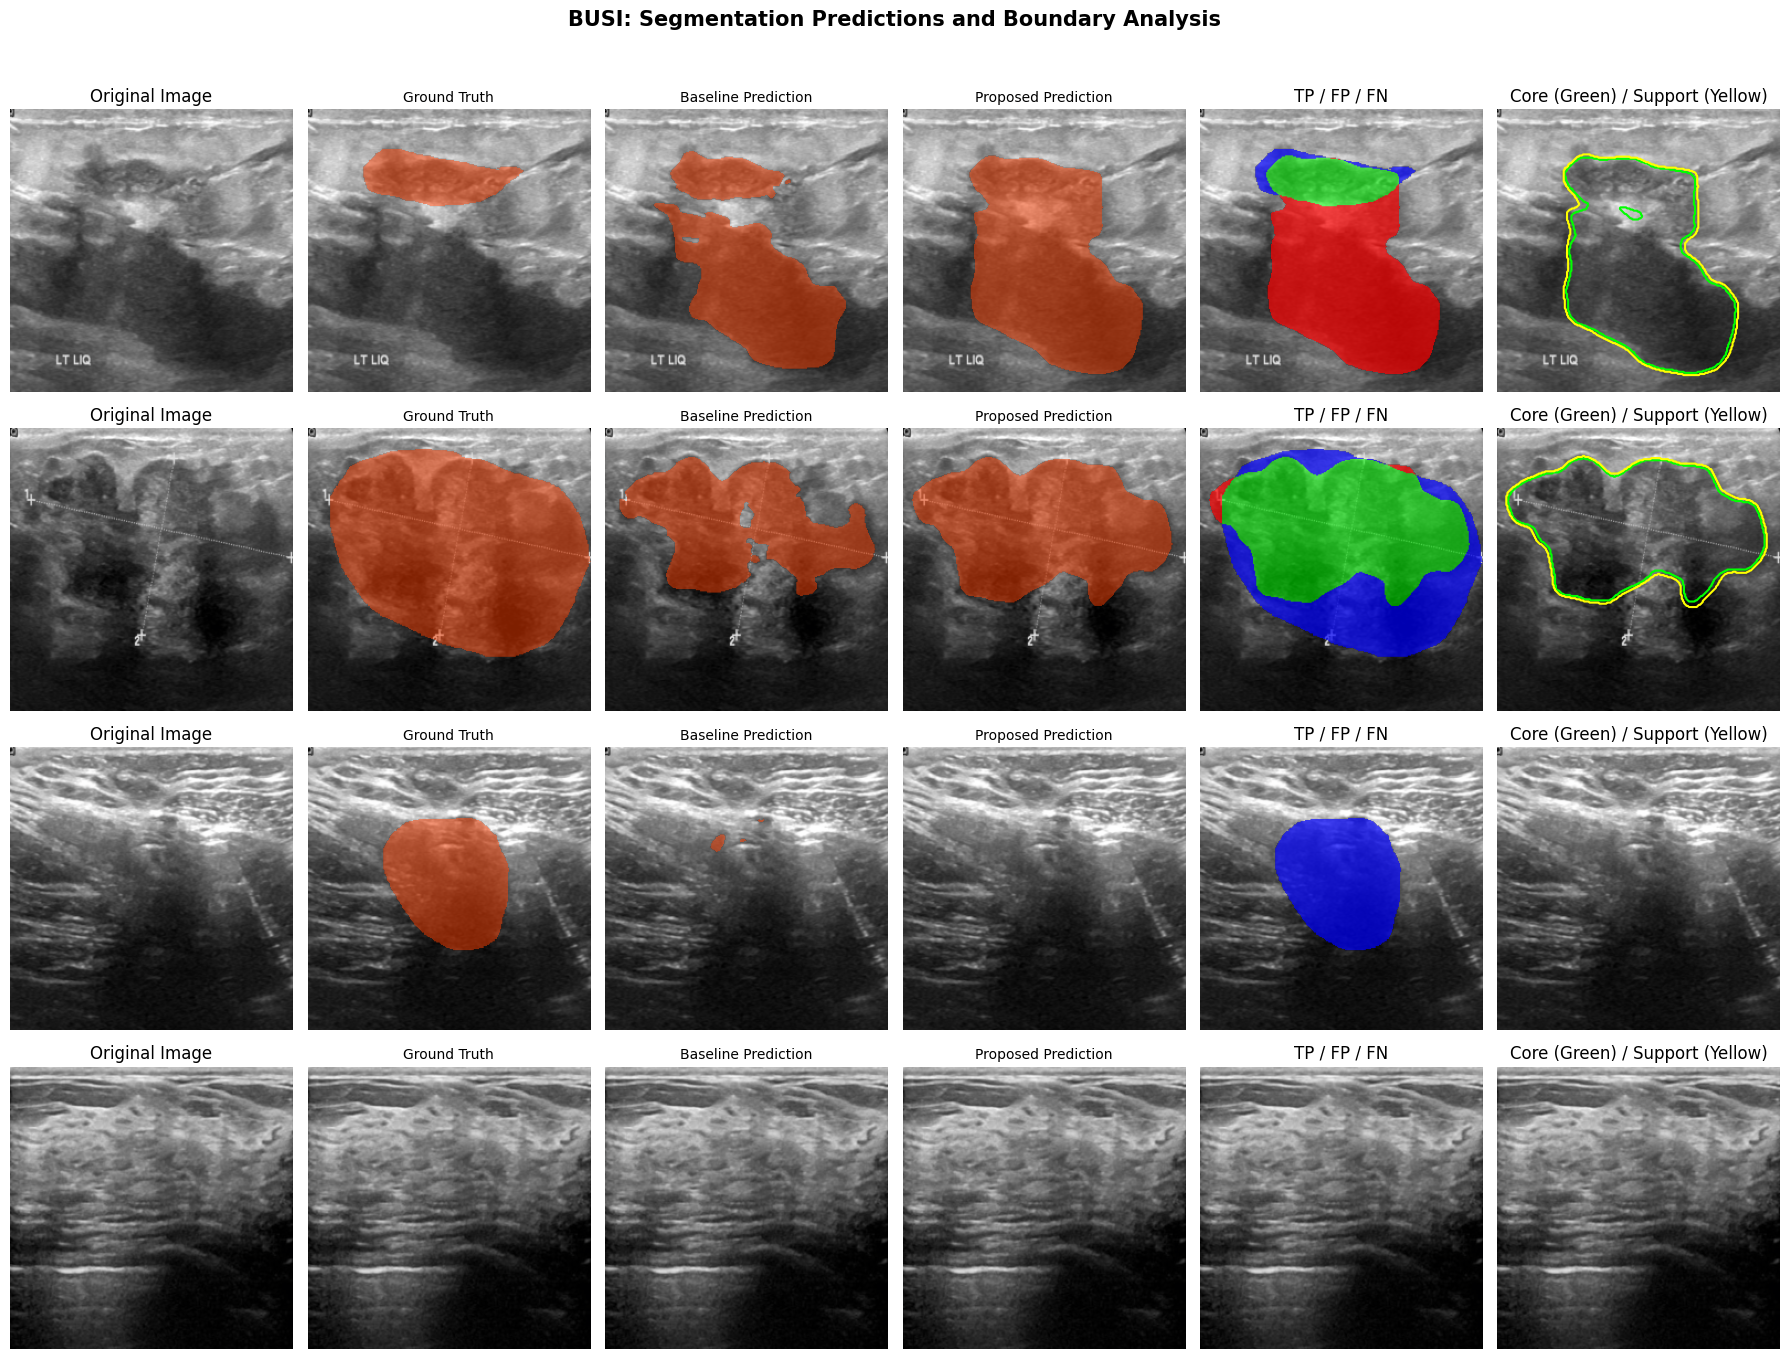


SEGMENTATION VISUALIZATION COMPLETED
           image  foreground_pixels  baseline_dice  proposed_dice  baseline_fp_pixels  proposed_fp_pixels  proposed_fn_pixels
benign (408).png               4940       0.292050       0.294674               13891               18226                 937
benign (141).png              33613       0.656676       0.770328                 136                 452               12273
benign (233).png              10768       0.030364       0.000000                   0                   0               10768
 normal (47).png                  0            NaN            NaN                   0                   0                   0

Saved figure: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/BUSI_Segmentation_Comparison.png
Saved sample metrics: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/BUSI_Visual_Sample_Metrics.csv

Cell 12 completed successfully.


In [25]:

# ============================================================
# CELL 12: SEGMENTATION VISUALIZATION AND ERROR ANALYSIS
# Dataset: BUSI
# Models: Baseline vs Proposed Region-Guided Model
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path

RUN_DIR = Path(RUN_DIR)

# ------------------------------------------------------------
# 1. LOAD TRAINED MODELS
# ------------------------------------------------------------

models = {}

for variant in ["baseline", "proposed"]:

    checkpoint_path = (
        RUN_DIR / "checkpoints" / f"{variant}_best.pt"
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(checkpoint_path)

    network = RegionSeg(
        variant=variant,
        pretrained=False
    ).to(DEVICE)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    network.load_state_dict(checkpoint["state_dict"])
    network.eval()

    models[variant] = network

    print(
        f"Loaded {variant}: "
        f"best checkpoint from epoch {checkpoint['epoch']}"
    )

# ------------------------------------------------------------
# 2. VALIDATION DATASET
# ------------------------------------------------------------

val_dataset = SegDataset(
    records,
    val,
    augment=False
)

positive_indices = []
empty_indices = []

for i, source_index in enumerate(val_dataset.indices):

    _, mask = load_image_and_mask(records[source_index])

    if mask.any():
        positive_indices.append(i)
    else:
        empty_indices.append(i)

print("Foreground validation images:", len(positive_indices))
print("Empty-mask validation images:", len(empty_indices))

# Deterministic sample selection (not based on model scores)
rng = np.random.default_rng(42)

selected = []

if positive_indices:
    selected.extend(
        rng.choice(
            positive_indices,
            size=min(3, len(positive_indices)),
            replace=False
        ).tolist()
    )

if empty_indices:
    selected.append(int(rng.choice(empty_indices)))

if not selected:
    raise RuntimeError("No validation samples available.")

# ------------------------------------------------------------
# 3. HELPER FUNCTIONS
# ------------------------------------------------------------

def denormalize_image(x):

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    img = x.permute(1, 2, 0).cpu().numpy()
    return np.clip(img * std + mean, 0, 1)


def calculate_dice(pred, truth):

    if not truth.any():
        return float("nan")

    intersection = np.logical_and(pred, truth).sum()

    return (
        2 * intersection /
        max(1, pred.sum() + truth.sum())
    )


def draw_overlay(ax, image, mask, title):

    ax.imshow(image)

    overlay = np.zeros(
        (*mask.shape, 4), dtype=np.float32
    )

    overlay[mask] = [1, 0.25, 0, 0.50]

    ax.imshow(overlay)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


# ------------------------------------------------------------
# 4. CREATE SEGMENTATION COMPARISON FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(selected),
    6,
    figsize=(18, 3.5 * len(selected)),
    squeeze=False
)

result_rows = []

for row, sample_index in enumerate(selected):

    x, y, _, _, _ = val_dataset[sample_index]

    image = denormalize_image(x)
    truth = y[0].numpy() >= 0.5

    predictions = {}

    with torch.no_grad():

        for variant, network in models.items():

            output = network(
                x.unsqueeze(0).to(DEVICE)
            )

            predictions[variant] = {
                key: value[0, 0].cpu().numpy()
                for key, value in output.items()
            }

    baseline = predictions["baseline"]["p"] >= 0.5
    proposed = predictions["proposed"]["p"] >= 0.5

    # Original image
    axes[row, 0].imshow(image)
    axes[row, 0].set_title("Original Image")
    axes[row, 0].axis("off")

    # Ground-truth overlay
    draw_overlay(
        axes[row, 1],
        image,
        truth,
        "Ground Truth"
    )

    # Baseline overlay
    draw_overlay(
        axes[row, 2],
        image,
        baseline,
        "Baseline Prediction"
    )

    # Proposed overlay
    draw_overlay(
        axes[row, 3],
        image,
        proposed,
        "Proposed Prediction"
    )

    # Error map
    tp = proposed & truth
    fp = proposed & ~truth
    fn = ~proposed & truth

    error_rgba = np.zeros(
        (*truth.shape, 4), dtype=np.float32
    )

    error_rgba[tp] = [0, 1, 0, 0.55]  # Green = correct
    error_rgba[fp] = [1, 0, 0, 0.70]  # Red = false positive
    error_rgba[fn] = [0, 0, 1, 0.70]  # Blue = missed lesion

    axes[row, 4].imshow(image)
    axes[row, 4].imshow(error_rgba)
    axes[row, 4].set_title("TP / FP / FN")
    axes[row, 4].axis("off")

    # Proposed core and outer-support contours
    core = predictions["proposed"]["c"] >= 0.5
    outer = predictions["proposed"]["o"] >= 0.5

    axes[row, 5].imshow(image)

    if core.any() and not core.all():
        axes[row, 5].contour(
            core.astype(float),
            levels=[0.5],
            colors=["lime"],
            linewidths=1.5
        )

    if outer.any() and not outer.all():
        axes[row, 5].contour(
            outer.astype(float),
            levels=[0.5],
            colors=["yellow"],
            linewidths=1.5
        )

    axes[row, 5].set_title(
        "Core (Green) / Support (Yellow)"
    )
    axes[row, 5].axis("off")

    baseline_dice = calculate_dice(baseline, truth)
    proposed_dice = calculate_dice(proposed, truth)

    source_index = val_dataset.indices[sample_index]

    result_rows.append({
        "image": records[source_index]["image"].name,
        "foreground_pixels": int(truth.sum()),
        "baseline_dice": baseline_dice,
        "proposed_dice": proposed_dice,
        "baseline_fp_pixels": int(
            np.logical_and(baseline, ~truth).sum()
        ),
        "proposed_fp_pixels": int(fp.sum()),
        "proposed_fn_pixels": int(fn.sum())
    })

fig.suptitle(
    "BUSI: Segmentation Predictions and Boundary Analysis",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

# ------------------------------------------------------------
# 5. SAVE FIGURE
# ------------------------------------------------------------

figure_path = RUN_DIR / "BUSI_Segmentation_Comparison.png"

fig.savefig(
    figure_path,
    dpi=250,
    bbox_inches="tight",
    facecolor="white",
    format="png"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. SAVE SAMPLE-LEVEL RESULTS
# ------------------------------------------------------------

sample_results = pd.DataFrame(result_rows)

csv_path = RUN_DIR / "BUSI_Visual_Sample_Metrics.csv"

sample_results.to_csv(csv_path, index=False)

print("\n" + "=" * 60)
print("SEGMENTATION VISUALIZATION COMPLETED")
print("=" * 60)

print(sample_results.to_string(index=False))

print("\nSaved figure:", figure_path)
print("Saved sample metrics:", csv_path)

print("\nCell 12 completed successfully.")


In [26]:
from google.colab import drive
import shutil

drive.mount("/content/drive")

destination = (
    Path("/content/drive/MyDrive")
    / "Medical_Lesion_Segmentation_Research"
    / RUN_DIR.name
)

destination.parent.mkdir(parents=True, exist_ok=True)

shutil.copytree(
    RUN_DIR,
    destination,
    dirs_exist_ok=True
)

print("Experiment backed up to:", destination)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Experiment backed up to: /content/drive/MyDrive/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z
